# LEV: Does corporate leverage help explain stock returns?

**Research question.** Does a long–short portfolio that buys high-leverage stocks and shorts low-leverage stocks earn a positive premium, perform differently in bad economic states, and/or add explanatory power beyond the market, size (SMB), value (HML), and momentum (UMD)?

**Proposed factor:** LEV, an equal-weight high-minus-low debt-to-market-capitalization portfolio. It is an additional candidate factor, not a renamed market, SMB, HML, or UMD factor.

**Intended audience:** Quantitative equity managers evaluating potential factor tilts and institutional investors (e.g. pension fund, insurance company) assessing whether a leverage product improves an existing factor portfolio. A factor tilt means deliberately increasing or decreasing a portfolio's exposure to a particular characteristic. For example, if your research found that high-leverage companies consistently earned higher risk-adjusted returns, a quantitative manager might increase the portfolio's exposure to high-leverage stocks. Institutional investors are professionals responsible for deciding how large pools of money are invested and typically evaluate investment strategies rather than selecting every individual stock themselves. If they propose adding a new strategy based on corporate leverage, the factor regressions help answer this question by testing whether LEV adds explanatory power beyond the established factors.

**Economic rationale and falsifiable hypothesis.** High debt increases fixed obligations, refinancing exposure, and sensitivity to falling cash flows. In recessions and negative-market months, investors may dislike this exposure; a positive average high-minus-low premium would be consistent with compensation for bearing bad-state risk. An alternative behavioral account is that investors misprice balance-sheet distress or extrapolate past performance. If high-leverage stocks fall sharply in bad times but LEV earns no reliable average premium, the evidence supports exposure to downside risk without establishing that the risk is rewarded.

## 1. Data Sources, Sample Selection, and Cleaning

There are two input CSVs: CRSP contains `PERMNO` (stock identifier), `MthCalDt` (monthly date), `MthCap` (capitalization in USD thousands), `MthRet` (monthly total return), stock-type flags, and `USIncFlg`. Compustat contains `GVKEY` (company identifier), annual statement date `datadate`, short-term debt `dlc`, long-term debt `dltt` (USD millions), `curcd` (currency), and linking fields. `LPERMNO` identifies the corresponding CRSP stock; `LINKDT` (date the company–stock relationship becomes valid) and `LINKENDDT` (date that relationship stops being valid) specify when that mapping is valid. Link dates are not accounting-publication dates.

**Rules, in execution order:**
1. Parse dates; normalize CRSP observations to calendar month-end. Use the preceding source month to compute the January 2010 lag.
2. Verify repeated `PERMNO`–month rows agree on `MthCap`, `MthRet` and `MthPrevCap`; then keep one detail row. Conflicting economic values raise an error instead of being arbitrarily selected.
3. Calculate `lag_cap` from the previous consecutive calendar month's actual `MthCap`; if that month is absent, leave the lag missing. `MthPrevCap` is used only to check duplicate consistency.
4. Restrict analysis months to January 2010 to December 2025 and eligible CRSP `EQTY`/`COM`/`NS`/`RW` observations, positive current and lagged cap, and observed total return.
5. Keep Compustat annual USD, industrial, consolidated, standard records with at least one debt component and `LC`/`LU`, primary `P`/`C` links. **Accounting availability assumption:** `available_date = datadate + six calendar months`; the month-end of this date must be no later than the return month. This is a conventional lag assumption, not a measured SEC filing date.
6. Use a backward stock-identifier as-of match to the most recently available annual record and require its link validity window to cover the stock month. A latest match failing its link window is dropped, rather than borrowing an older report.

**Universe:** All eligible matched USD-reporting stocks regardless of `USIncFlg`; U.S.-incorporated-only is a separate sensitivity test.

**Return convention:** Monthly stock returns are obtained from CRSP using `MthRet`, which measures total holding-period returns, including dividends and adjustments for corporate actions such as stock splits and distributions. This ensures that portfolio returns reflect the overall economic return earned by investors rather than changes in stock prices alone. The same return measure is used consistently when constructing the high- and low-leverage portfolios and calculating the monthly leverage factor. Monthly factor and portfolio returns are expressed as decimals and displayed means are multiplied by 100 to show percent/month.

In [3]:
import pandas as pd, numpy as np, statsmodels.api as sm
from pathlib import Path
from IPython.display import display
P=Path('.')
raw_c=pd.read_csv(P/'03_Compustat_Annual_and_Link_Source_Data.csv',low_memory=False)
raw_r=pd.read_csv(P/'02_CRSP_Monthly_Source_Data.csv',low_memory=False)
assert not {'available_date','lag_cap','signal','debt_millions','q','portfolio_label'}.intersection(set(raw_c.columns)|set(raw_r.columns))
raw_c['datadate']=pd.to_datetime(raw_c.datadate,errors='coerce')
raw_c['LINKDT']=pd.to_datetime(raw_c.LINKDT,errors='coerce')
raw_c['LINKENDDT']=pd.to_datetime(raw_c.LINKENDDT,format='mixed',errors='coerce')
raw_r['date']=pd.to_datetime(raw_r.MthCalDt,errors='coerce').dt.to_period('M').dt.to_timestamp('M')
comp_source_n=len(raw_c); crsp_source_n=len(raw_r)
print('Uploaded source: Compustat rows',comp_source_n,'CRSP rows',crsp_source_n)
print('Actual CRSP range:',raw_r.date.min().date(),'to',raw_r.date.max().date())
assert raw_r.date.max() < pd.Timestamp('2026-01-01'), 'Update date-window description if new CRSP is supplied'
# Retain original market capitalization observations before analysis screens, to compute calendar-month lag.
economics=['MthCap','MthRet','MthPrevCap']
conflicts=raw_r.groupby(['PERMNO','date'],dropna=False)[economics].nunique(dropna=False).gt(1).any(axis=1)
assert not conflicts.any(), f'Conflicting CRSP duplicate stock-months: {int(conflicts.sum())}'
r=(raw_r.sort_values(['PERMNO','date','SecInfoStartDt'])
   .drop_duplicates(['PERMNO','date'],keep='last').copy())
crsp_unique_n=len(r); crsp_duplicates_removed=crsp_source_n-crsp_unique_n
r['lag_cap']=r.groupby('PERMNO').MthCap.shift(1)
prior=r.groupby('PERMNO').date.shift(1)
gap=(r.date.dt.year-prior.dt.year)*12+r.date.dt.month-prior.dt.month
r.loc[gap.ne(1),'lag_cap']=np.nan
print('CRSP duplicate detail rows removed:',len(raw_r)-len(r))
r=r[r.date.between('2010-01-01','2025-12-31')].copy()
crsp_in_period_n=len(r); crsp_outside_n=crsp_unique_n-crsp_in_period_n
screens=(r.SecurityType.eq('EQTY') & r.SecuritySubType.eq('COM') &
         r.ShareType.eq('NS') & r.ConditionalType.eq('RW') &
         r.MthCap.gt(0) & r.lag_cap.gt(0) & r.MthRet.notna())
print('CRSP screened:',len(r),'→',int(screens.sum()))
crsp_screen_removed=crsp_in_period_n-int(screens.sum()); r=r.loc[screens].copy(); crsp_screened_n=len(r)
del raw_r
# Annual financial records: standard industrial USD reporting, linked to CRSP.
c=raw_c.loc[(raw_c.curcd.eq('USD')) & raw_c.indfmt.eq('INDL') &
            raw_c.consol.eq('C') & raw_c.popsrc.eq('D') & raw_c.datafmt.eq('STD') &
            raw_c.LINKTYPE.isin(['LC','LU']) & raw_c.LINKPRIM.isin(['P','C']) &
            raw_c.LPERMNO.notna() & raw_c.datadate.notna() &
            raw_c[['dlc','dltt']].notna().any(axis=1)].copy()
comp_screened_n=len(c); comp_screen_removed=comp_source_n-comp_screened_n
c['PERMNO']=c.LPERMNO.astype('int64')
del raw_c
c['available_date']=c.datadate+pd.DateOffset(months=6)
c['available_month']=c.available_date.dt.to_period('M').dt.to_timestamp('M')
c['LINKENDDT']=c.LINKENDDT.fillna(pd.Timestamp('2099-12-31'))
# Preserve distinct link windows, prefer primary P when multiple accounting rows remain.
c['link_priority']=c.LINKPRIM.map({'P':0,'C':1})
c=c.sort_values(['PERMNO','available_month','datadate','link_priority']).drop_duplicates(
    ['PERMNO','datadate','LINKDT','LINKENDDT'],keep='first')
# Memory-efficient as-of match by PERMNO: latest available accounting record per stock-month.
# Link-window validity is verified after the match; a failed match is excluded rather than
# silently borrowing an older report from a different link window.
comp_duplicates_removed=comp_screened_n-len(c)
c=c.sort_values(['available_month','PERMNO']).copy()
r=r.sort_values(['date','PERMNO']).copy()
d=pd.merge_asof(r,c,left_on='date',right_on='available_month',by='PERMNO',
                direction='backward',allow_exact_matches=True,suffixes=('','_comp'))
d=d.loc[d.datadate.notna() & (d.LINKDT<=d.date) & (d.date<=d.LINKENDDT)].copy()
d=d.rename(columns={'GVKEY':'gvkey','conm':'company_name'})
d=d.sort_values(['PERMNO','date'])
assert not d.duplicated(['PERMNO','date']).any()
assert (d.available_month<=d.date).all()
print('Matched eligible USD-reporting stock-months:',len(d),'| stocks:',d.PERMNO.nunique(),
      '| observed months:',d.date.nunique())
print('USIncFlg counts:',d.USIncFlg.value_counts(dropna=False).to_dict())
display(d[['date','PERMNO','gvkey','datadate','available_date','lag_cap','MthCap','MthRet','dlc','dltt']].head(10))

Uploaded source: Compustat rows 87869 CRSP rows 1546335
Actual CRSP range: 2009-12-31 to 2025-12-31
CRSP duplicate detail rows removed: 19279
CRSP screened: 1520330 → 883242
Matched eligible USD-reporting stock-months: 765146 | stocks: 8613 | observed months: 192
USIncFlg counts: {'Y': 681693, 'N': 83453}


,date,PERMNO,gvkey,datadate,available_date,lag_cap,MthCap,MthRet,dlc,dltt
22782,2010-06-30,10001,12994.0,2009-12-31,2010-06-30,69209.40,66028.80,-0.043732,15.315,13.003
27327,2010-07-31,10001,12994.0,2009-12-31,2010-06-30,66028.80,71257.60,0.083605,15.315,13.003
31849,2010-08-31,10001,12994.0,2009-12-31,2010-06-30,71257.60,62983.08,-0.111716,15.315,13.003
36370,2010-09-30,10001,12994.0,2009-12-31,2010-06-30,62983.08,67531.76,0.076567,15.315,13.003
40882,2010-10-31,10001,12994.0,2009-12-31,2010-06-30,67531.76,69485.95,0.032909,15.315,13.003
45380,2010-11-30,10001,12994.0,2009-12-31,2010-06-30,69485.95,78653.36,-0.118336,15.315,13.003
49861,2010-12-31,10001,12994.0,2009-12-31,2010-06-30,78653.36,82413.68,0.052308,15.315,13.003
54325,2011-01-31,10001,12994.0,2009-12-31,2010-06-30,82413.68,84450.52,0.029061,15.315,13.003
58799,2011-02-28,10001,12994.0,2009-12-31,2010-06-30,84450.52,86017.32,0.022777,15.315,13.003
63267,2011-03-31,10001,12994.0,2009-12-31,2010-06-30,86017.32,91892.82,0.072661,15.315,13.003


## 2. Winsorization and Portfolio Formation

Compustat reports `dlc` (current debt) and `dltt` (long-term debt) in USD millions. Their sum gives total debt; a missing component is treated as zero only when the other component is reported. The sorting signal divides the most recently available annual debt by previous-month market capitalization, converting CRSP's `lag_cap` from USD thousands to USD millions first. The six-month accounting availability rule has already been applied during matching, so debt is not lagged a second time.

For each calendar month, the notebook separately winsorizes the leverage signal and CRSP monthly total returns at the 1st and 99th percentiles. Winsorization clips extreme values rather than deleting observations.

Each month, eligible stocks are ranked by the winsorized debt-to-lagged-market-capitalization signal. Deterministic rank ties divide stocks into five approximately equal-count portfolios: Q1 has the lowest leverage signal and Q5 the highest. Each leg earns the equal-weight average of its constituents' winsorized CRSP dividend-inclusive monthly total returns. The final factor is a long-short portfolio: `LEV = Q5 − Q1`. Long Q5: Take a positive investment position in the highest-leverage stocks. Short Q1: Take a negative investment position in the lowest-leverage stocks.

In [5]:
d['debt_millions']=d[['dlc','dltt']].fillna(0).sum(axis=1)
d['sorting_debt_millions']=d['debt_millions'] # most recent available accounting report, no second lag
d['signal']=d.sorting_debt_millions/(d.lag_cap/1000)
d=d.loc[np.isfinite(d.signal) & d.MthRet.notna() & d.lag_cap.gt(0)].copy()
def monthly_winsor(s):
    return s.clip(lower=s.quantile(.01),upper=s.quantile(.99))
d['signal_w']=d.groupby('date').signal.transform(monthly_winsor)
d['ret_w']=d.groupby('date').MthRet.transform(monthly_winsor)
d['q']=d.groupby('date').signal_w.transform(
    lambda s:pd.qcut(s.rank(method='first'),5,labels=False)+1).astype(int)
d['portfolio_label']='Q'+d.q.astype(str)
membership_columns=['date','portfolio_label','q','PERMNO','gvkey','company_name','Ticker',
                    'USIncFlg','datadate','available_date','debt_millions','signal','signal_w',
                    'MthRet','ret_w','lag_cap']
d[membership_columns].sort_values(['date','q','PERMNO']).to_csv(
    P/'05_Leverage_Portfolio_Memberships.csv',index=False)
print('Created all timing, factor, and membership variables inside notebook.')
print('Exported membership rows:',len(d))
display(d[membership_columns].head(10))

Created all timing, factor, and membership variables inside notebook.
Exported membership rows: 765146


,date,portfolio_label,q,PERMNO,gvkey,company_name,Ticker,USIncFlg,datadate,available_date,debt_millions,signal,signal_w,MthRet,ret_w,lag_cap
22782,2010-06-30,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.409164,0.409164,-0.043732,-0.043732,69209.40
27327,2010-07-31,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.428873,0.428873,0.083605,0.083605,66028.80
31849,2010-08-31,Q3,3,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.397403,0.397403,-0.111716,-0.111716,71257.60
36370,2010-09-30,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.449613,0.449613,0.076567,0.076567,62983.08
40882,2010-10-31,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.419329,0.419329,0.032909,0.032909,67531.76
45380,2010-11-30,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.407536,0.407536,-0.118336,-0.118336,69485.95
49861,2010-12-31,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.360035,0.360035,0.052308,0.052308,78653.36
54325,2011-01-31,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.343608,0.343608,0.029061,0.029061,82413.68
58799,2011-02-28,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.335321,0.335321,0.022777,0.022777,84450.52
63267,2011-03-31,Q4,4,10001,12994.0,GAS NATURAL INC,EGAS,Y,2009-12-31,2010-06-30,28.318,0.329213,0.329213,0.072661,0.072661,86017.32


The following summary is generated from the cleaning and winsorization process above. It reports original observations, duplicate detail records removed after checking agreement on economic fields, sample and eligibility exclusions, valid accounting matches, remaining missingness, and values changed by monthly winsorization.

In [7]:
audit=pd.Series({
 'CRSP_source_detail_rows':crsp_source_n,
 'CRSP_duplicate_detail_rows_removed':crsp_duplicates_removed,
 'CRSP_unique_stock_months_after_deduplication':crsp_unique_n,
 'CRSP_rows_outside_analysis_dates_including_history_buffer':crsp_outside_n,
 'CRSP_stock_months_in_2010_to_2025_before_screens':crsp_in_period_n,
 'CRSP_stock_months_removed_by_combined_eligibility_screens':crsp_screen_removed,
 'CRSP_stock_months_after_screens':crsp_screened_n,
 'Compustat_source_annual_link_rows':comp_source_n,
 'Compustat_rows_removed_by_annual_link_eligibility_screens':comp_screen_removed,
 'Compustat_eligible_rows_before_link_deduplication':comp_screened_n,
 'Compustat_duplicate_link_rows_removed':comp_duplicates_removed,
 'CRSP_stock_months_without_valid_available_accounting_match':crsp_screened_n-len(d),
 'final_matched_stock_months':len(d),
 'distinct_stocks':d.PERMNO.nunique(),
 'factor_months':d.date.nunique(),
 'duplicate_stock_months_remaining':int(d.duplicated(['PERMNO','date']).sum()),
 'missing_total_returns_remaining':int(d.MthRet.isna().sum()),
 'missing_sort_signal_remaining':int(d.signal_w.isna().sum()),
 'return_values_changed_by_1_99_winsorization':int((d.MthRet-d.ret_w).abs().gt(1e-12).sum()),
 'signal_values_changed_by_1_99_winsorization':int((d.signal-d.signal_w).abs().gt(1e-12).sum())})
display(audit.to_frame('count'))

,count
CRSP_source_detail_rows,1546335
CRSP_duplicate_detail_rows_removed,19279
CRSP_unique_stock_months_after_deduplication,1527056
CRSP_rows_outside_analysis_dates_including_history_buffer,6726
CRSP_stock_months_in_2010_to_2025_before_screens,1520330
CRSP_stock_months_removed_by_combined_eligibility_screens,637088
CRSP_stock_months_after_screens,883242
Compustat_source_annual_link_rows,87869
Compustat_rows_removed_by_annual_link_eligibility_screens,8899
Compustat_eligible_rows_before_link_deduplication,78970


## 3. Baseline Leverage Premium

The baseline premium is the monthly high-minus-low return, Q5 minus Q1. Its mean is estimated with an intercept-only OLS regression using six-lag Newey–West/HAC standard errors. The t-statistic and p-value assess whether the average monthly factor return differs from zero; they are not portfolio factor loadings. Regression inputs use decimal returns, while displayed monthly means are percentages.

In [9]:
def form_factor(x, k=5, value_weighted=False):
    x=x.copy()
    x['bucket']=x.groupby('date').signal_w.transform(lambda s:pd.qcut(s.rank(method='first'),k,labels=False)+1)
    if value_weighted:
        g=x.groupby(['date','bucket']).apply(lambda v:np.average(v.ret_w,weights=v.lag_cap),include_groups=False).unstack()
    else: g=x.groupby(['date','bucket']).ret_w.mean().unstack()
    out=pd.DataFrame({'low':g[1], 'high':g[k]});out['LEV']=out.high-out.low
    return out

def mean_test(s):
    s=s.dropna();m=sm.OLS(s,np.ones((len(s),1))).fit(cov_type='HAC',cov_kwds={'maxlags':6})
    return {'months':len(s),'mean_monthly_pct':100*s.mean(),'t_HAC':float(m.tvalues.iloc[0]),'p_HAC':float(m.pvalues.iloc[0])}
factor=form_factor(d)
display(pd.DataFrame([mean_test(factor.LEV)],index=['Baseline LEV']).round(4))
print('LEV is high leverage minus low leverage, using winsorized total returns.')

,months,mean_monthly_pct,t_HAC,p_HAC
Baseline LEV,192,0.3139,0.9534,0.3404


LEV is high leverage minus low leverage, using winsorized total returns.


## 4. Size-Sorted Test Portfolios

Each month, independently sort eligible stocks into 5 equal-count groups on the previous month's market capitalization (`lag_cap`), not the leverage signal. Each size test asset earns the equal-weight mean of its constituent stocks' monthly winsorized total returns. These are five time-series portfolios, from Size1 (smallest) to Size5 (largest). They are not independent external holdings; some stocks also appear in LEV, which limits causal/out-of-sample interpretations. Section 7 uses their excess returns after subtracting the published risk-free rate.

In [11]:
d['size_q']=d.groupby('date').lag_cap.transform(lambda s:pd.qcut(s.rank(method='first'),5,labels=False)+1)
size=d.groupby(['date','size_q']).ret_w.mean().unstack().rename(columns=lambda x:f'Size{x}')
print('Five independent size test portfolios:',size.columns.tolist())

Five independent size test portfolios: ['Size1', 'Size2', 'Size3', 'Size4', 'Size5']


## 5. Benchmark Factors and Return Conventions

Read the csv file containing Kenneth R. French benchmark input. `Mkt_RF` = market excess return; `SMB` = size; `HML` = value; `Mom` = momentum (UMD equivalent); `RF` = risk-free return. All are monthly decimal returns, aligned on calendar month-end; the provided benchmark file was prepared from the published percentage series by dividing by 100.

In [13]:
ff=pd.read_csv(P/'04_Fama_French_Monthly_Factors.csv',parse_dates=['date']).set_index('date')
assert ff.index.is_unique
assert ff[['Mkt_RF','SMB','HML','Mom','RF']].notna().all().all()
print('Benchmark period:',ff.index.min().date(),'to',ff.index.max().date())
display(ff.head(10))

Benchmark period: 2010-01-31 to 2025-12-31


,Mkt_RF,SMB,HML,Mom,RF
date,,,,,
2010-01-31,-0.0335,0.0043,0.0033,-0.0531,0.0000
2010-02-28,0.0339,0.0118,0.0318,0.0370,0.0000
2010-03-31,0.0630,0.0146,0.0219,0.0358,0.0001
2010-04-30,0.0199,0.0484,0.0296,0.0319,0.0001
2010-05-31,-0.0790,0.0013,-0.0248,-0.0018,0.0001
2010-06-30,-0.0556,-0.0179,-0.0473,-0.0270,0.0001
2010-07-31,0.0692,0.0023,-0.0049,0.0177,0.0001
2010-08-31,-0.0478,-0.0301,-0.0173,-0.0006,0.0001
2010-09-30,0.0955,0.0382,-0.0302,0.0135,0.0001


## 6. Regression Results and Incremental Explanatory Power

For each of 5 size-sorted test portfolios, regress its monthly excess return (`portfolio total return − RF`) on a constant and **(a) market alone (CAPM)**, **(b) market + LEV**, **(c) market + SMB + HML (FF3)**, **(d) FF3 + LEV**, **(e) FF3 + momentum (UMD)**, and **(f) FF3 + momentum + LEV**. This directly supplies the required market-controlled LEV regression and stronger alternative benchmarks.

OLS coefficients are estimated conventionally; inference uses six-lag HAC standard errors. The table reports the LEV loading (beta), its `t` and `p`, model R², adjusted R², and alpha (intercept). For models without LEV, its beta/t/p entries are blank. Compare matched model pairs on the same 192 months and report average changes in adjusted R² across the 5 test assets. Significant beta ≠ significant average LEV premium; increased in-sample fit ≠ profitable strategy.

In [15]:
joined=size.join(factor[['LEV']]).join(ff,how='inner').dropna()
assert len(joined)>60, 'Insufficient benchmark overlap'
models={'CAPM':['Mkt_RF'],'CAPM + LEV':['Mkt_RF','LEV'],'FF3':['Mkt_RF','SMB','HML'],'FF3 + LEV':['Mkt_RF','SMB','HML','LEV'],'FF3 + Mom':['Mkt_RF','SMB','HML','Mom'],'FF3 + Mom + LEV':['Mkt_RF','SMB','HML','Mom','LEV']}
rows=[]
for asset in size.columns:
    y=joined[asset]-joined.RF
    for model,features in models.items():
        fit=sm.OLS(y,sm.add_constant(joined[features])).fit(cov_type='HAC',cov_kwds={'maxlags':6})
        rows.append({'portfolio':asset,'model':model,'months':len(y),'alpha_monthly_pct':100*fit.params['const'],'alpha_t':fit.tvalues['const'],'LEV_beta':fit.params.get('LEV',np.nan),'LEV_t':fit.tvalues.get('LEV',np.nan),'LEV_p':fit.pvalues.get('LEV',np.nan),'R2':fit.rsquared,'adjusted_R2':fit.rsquared_adj})
reg=pd.DataFrame(rows)
display(reg.round(4))
for base,plus in [('CAPM','CAPM + LEV'),('FF3','FF3 + LEV'),('FF3 + Mom','FF3 + Mom + LEV')]:
    a=reg[reg.model.eq(base)].set_index('portfolio');b=reg[reg.model.eq(plus)].set_index('portfolio')
    print(base,'→ +LEV: mean change in adjusted R²:',round((b.adjusted_R2-a.adjusted_R2).mean(),4),'significant LEV portfolios:',int((b.LEV_p<.05).sum()),'of',len(b))

,portfolio,model,months,alpha_monthly_pct,alpha_t,LEV_beta,LEV_t,LEV_p,R2,adjusted_R2
0,Size1,CAPM,192,-1.8754,-4.2805,NaN,NaN,NaN,0.4547,0.4518
1,Size1,CAPM + LEV,192,-1.8911,-4.3340,0.2135,1.6432,0.1003,0.4650,0.4594
2,Size1,FF3,192,-1.5304,-4.0804,NaN,NaN,NaN,0.5933,0.5868
3,Size1,FF3 + LEV,192,-1.6075,-4.4217,0.5047,2.6664,0.0077,0.6204,0.6123
4,Size1,FF3 + Mom,192,-1.3967,-3.7805,NaN,NaN,NaN,0.6163,0.6081
5,Size1,FF3 + Mom + LEV,192,-1.5055,-4.2417,0.3605,2.1195,0.0340,0.6265,0.6164
6,Size2,CAPM,192,-0.7875,-3.4496,NaN,NaN,NaN,0.7122,0.7107
7,Size2,CAPM + LEV,192,-0.8048,-3.5787,0.2356,2.7883,0.0053,0.7289,0.7260
8,Size2,FF3,192,-0.4042,-3.9251,NaN,NaN,NaN,0.9222,0.9209
9,Size2,FF3 + LEV,192,-0.4235,-3.8966,0.1267,1.5310,0.1258,0.9244,0.9228


CAPM → +LEV: mean change in adjusted R²: 0.0124 significant LEV portfolios: 4 of 5
FF3 → +LEV: mean change in adjusted R²: 0.0057 significant LEV portfolios: 2 of 5
FF3 + Mom → +LEV: mean change in adjusted R²: 0.0016 significant LEV portfolios: 1 of 5


## 7. Robustness Across Portfolio and Sample Choices

The table repeats the baseline six-lag HAC mean test for: **value-weighted** Q5−Q1 legs (weights are preceding-month market cap); **terciles** rather than quintiles; **2010–2019** and **2020–2025** subperiods; and **U.S.-incorporated-only** firms. The main sample remains all eligible USD-reporting firms, not U.S.-only. Compare both the **sign and magnitude** of the premium and its `p_HAC`; do not call a result robust simply because the mean stays positive. Section 6 separately tests sensitivity of explanatory power to the **CAPM, FF3, and FF3+momentum** benchmark choice, including significance counts for LEV loadings and changes in adjusted R².

In [17]:
tests=[('Equal-weight quintiles',d,5,False),('Value-weight quintiles',d,5,True),('Equal-weight terciles',d,3,False),('2010–2019',d[d.date<'2020-01-01'],5,False),('2020–2025',d[d.date>='2020-01-01'],5,False),('US-incorporated only',d[d.USIncFlg.eq('Y')],5,False)]
rob=pd.DataFrame([{'specification':name,**mean_test(form_factor(x,k,w).LEV)} for name,x,k,w in tests])
display(rob.round(4))
print('Main sample:',len(d),'stock-month observations; US-incorporated-only subset:',int(d.USIncFlg.eq('Y').sum()))


,specification,months,mean_monthly_pct,t_HAC,p_HAC
0,Equal-weight quintiles,192,0.3139,0.9534,0.3404
1,Value-weight quintiles,192,-0.2537,-0.6202,0.5351
2,Equal-weight terciles,192,0.2480,0.8975,0.3695
3,2010–2019,120,-0.0556,-0.2415,0.8092
4,2020–2025,72,0.9299,1.2536,0.2100
5,US-incorporated only,192,0.3692,1.1488,0.2506


Main sample: 765146 stock-month observations; US-incorporated-only subset: 681693


## 8. Leverage Returns During Market Downturns

Define bad states before interpreting returns: (1) `Mkt_RF < 0` (negative market excess return), (2) a severe market decline `Mkt_RF ≤ −5%`, (3) the **three NBER recession months February to April 2020** represented in this 2010 to 2025 sample, and (4) the **two-month February to March 2020 COVID crash**. The market definitions and the recession/COVID dates can overlap; they are not independent subsamples. The table reports the number of months and Q1, Q5, and LEV means in each condition.

The market-stress analysis examines whether the leverage factor (LEV) performs differently during adverse market conditions. For stress categories containing at least 12 monthly observations, a HAC-adjusted test is used to assess whether the average LEV return is statistically different from zero. A separate regression compares average LEV returns during stress months with returns during other months. This distinction is important because a significantly negative average return during stressful periods does not necessarily mean that the difference between stress and non-stress returns is statistically significant. Both tests are therefore reported separately to avoid overstating the findings.

The COVID-19 recession and initial market-crash periods contain only three and two monthly observations, respectively, which are insufficient for reliable standalone statistical inference. Their average returns are presented as descriptive evidence of how the leverage factor behaved during those specific events. Furthermore, because multiple stress conditions are examined without applying a multiple-testing correction, the results should be interpreted as exploratory rather than conclusive. Negative LEV returns during market downturns are consistent with the possibility that highly leveraged companies are more vulnerable during adverse economic conditions. However, these findings alone cannot establish whether the observed pattern reflects rational compensation for financial risk, behavioral mispricing, or other market mechanisms.

Observed factor months: 192 | NBER recession months represented: 3


,condition,months,Q1_low_mean_pct,Q5_high_mean_pct,LEV_mean_pct,LEV_HAC_t,LEV_HAC_p
0,Down-market: Mkt_RF < 0,64,-4.9239,-5.2697,-0.3458,-0.5458,0.5852
1,Nonnegative market: Mkt_RF >= 0,128,3.0496,3.6935,0.6438,1.7284,0.0839
2,Severe decline: Mkt_RF <= -5%,19,-9.8206,-11.0335,-1.2129,-2.5164,0.0119
3,Other than severe decline,173,1.5134,1.9950,0.4816,1.5555,0.1198
4,NBER recession: Feb-Apr 2020,3,-1.3270,-5.7637,-4.4368,NaN,NaN
5,Outside NBER recession,189,0.4191,0.8084,0.3894,1.2325,0.2178
6,COVID crash: Feb-Mar 2020,2,-11.9048,-21.3566,-9.4518,NaN,NaN
7,Outside COVID crash window,190,0.5212,0.9380,0.4167,1.3375,0.1811


,comparison,stress_months,other_months,LEV_difference_pct,diff_HAC_t,diff_HAC_p
0,Down market vs nonnegative,64,128,-0.9896,-1.4469,0.1479
1,Severe decline vs other months,19,173,-1.6945,-1.3471,0.1779
2,NBER recession vs other months,3,189,-4.8261,NaN,NaN
3,COVID crash vs other months,2,190,-9.8685,NaN,NaN


Blank inference entries indicate fewer than 12 stress/comparison months, not a p-value of zero.


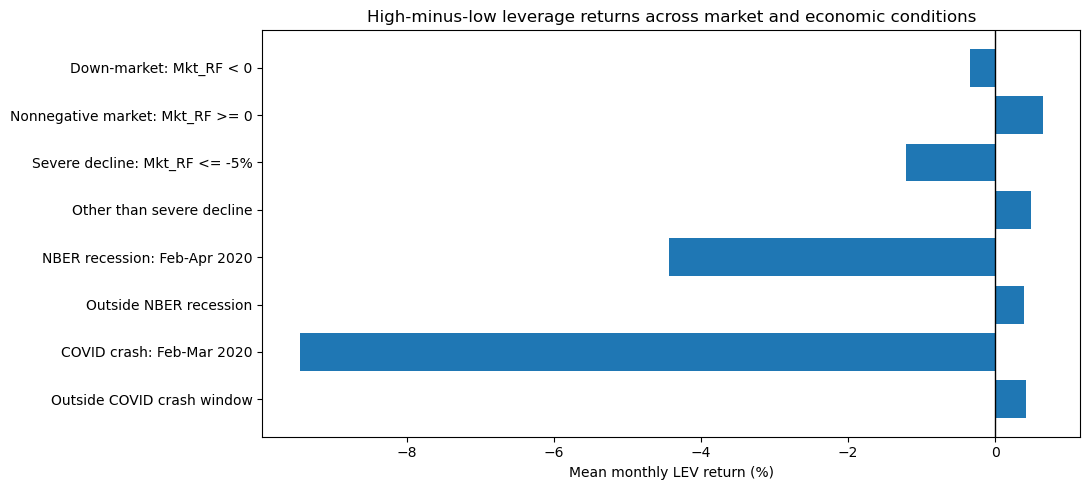

In [19]:
# Merge each month's Q1, Q5 and LEV with the official market factor; align calendar month-end.
stress=factor[['low','high','LEV']].join(ff[['Mkt_RF']],how='inner').dropna().sort_index()
stress.index=pd.to_datetime(stress.index).to_period('M').to_timestamp('M')
assert stress.index.is_unique
stress['down_market']=stress.Mkt_RF.lt(0)
stress['severe_decline']=stress.Mkt_RF.le(-.05)
stress['recession_2020']=stress.index.to_period('M').isin(pd.period_range('2020-02','2020-04',freq='M'))
stress['covid_crash']=stress.index.to_period('M').isin(pd.period_range('2020-02','2020-03',freq='M'))

conditions=[
 ('Down-market: Mkt_RF < 0',stress.down_market),
 ('Nonnegative market: Mkt_RF >= 0',~stress.down_market),
 ('Severe decline: Mkt_RF <= -5%',stress.severe_decline),
 ('Other than severe decline',~stress.severe_decline),
 ('NBER recession: Feb-Apr 2020',stress.recession_2020),
 ('Outside NBER recession',~stress.recession_2020),
 ('COVID crash: Feb-Mar 2020',stress.covid_crash),
 ('Outside COVID crash window',~stress.covid_crash)]
def conditional_summary(label,mask):
    x=stress.loc[mask,['low','high','LEV']]
    ans={'condition':label,'months':len(x),'Q1_low_mean_pct':100*x.low.mean(),
         'Q5_high_mean_pct':100*x.high.mean(),'LEV_mean_pct':100*x.LEV.mean()}
    if len(x)>=12:
        t=mean_test(x.LEV)
        ans.update(LEV_HAC_t=t['t_HAC'],LEV_HAC_p=t['p_HAC'])
    else:
        ans.update(LEV_HAC_t=np.nan,LEV_HAC_p=np.nan)
    return ans
stress_table=pd.DataFrame([conditional_summary(label,mask) for label,mask in conditions])
print('Observed factor months:',len(stress),'| NBER recession months represented:',int(stress.recession_2020.sum()))
display(stress_table.round(4))
diff_rows=[]
for label,mask in [('Down market vs nonnegative',stress.down_market),
                   ('Severe decline vs other months',stress.severe_decline),
                   ('NBER recession vs other months',stress.recession_2020),
                   ('COVID crash vs other months',stress.covid_crash)]:
    row={'comparison':label,'stress_months':int(mask.sum()),'other_months':int((~mask).sum()),
         'LEV_difference_pct':100*(stress.loc[mask,'LEV'].mean()-stress.loc[~mask,'LEV'].mean())}
    if mask.sum()>=12 and (~mask).sum()>=12:
        fit=sm.OLS(stress.LEV,sm.add_constant(mask.astype(int).rename('stress'))).fit(
            cov_type='HAC',cov_kwds={'maxlags':6})
        row.update(diff_HAC_t=fit.tvalues['stress'],diff_HAC_p=fit.pvalues['stress'])
    else: row.update(diff_HAC_t=np.nan,diff_HAC_p=np.nan)
    diff_rows.append(row)
stress_differences=pd.DataFrame(diff_rows)
display(stress_differences.round(4))
print('Blank inference entries indicate fewer than 12 stress/comparison months, not a p-value of zero.')

# A focused comparison plot; descriptive bars, not confidence intervals.
import matplotlib.pyplot as plt
plot=stress_table.iloc[[0,1,2,3,4,5,6,7]]
fig,ax=plt.subplots(figsize=(11,5))
ax.barh(plot['condition'],plot['LEV_mean_pct'])
ax.axvline(0,linewidth=1,color='black')
ax.set_xlabel('Mean monthly LEV return (%)')
ax.set_title('High-minus-low leverage returns across market and economic conditions')
ax.invert_yaxis()
fig.tight_layout()
plt.show()

## 9. Findings, Economic Explanations, and Investment Implications

All means are monthly returns; significance uses six-lag HAC/Newey–West tests unless otherwise noted.

### A. Baseline premium

The sample contains **765,146 eligible stock-months**, **8,613 stocks**, and **192 monthly factor observations (January 2010–December 2025)**. It includes both U.S.-incorporated and other eligible USD-reporting companies. The equal-weight high-minus-low leverage return is **+0.3139% per month** (HAC **t = 0.9534; p = 0.3404**). The mean is positive but **not statistically distinguishable from zero at 5%**. Do not interpret this as a reliable standalone premium.

### B. Robustness of the mean premium

| Specification | Mean LEV / month | HAC p-value | Meaning |
|:--|--:|--:|:--|
| Baseline equal-weight quintiles | +0.3139% | 0.3404 | Positive but insignificant |
| Value-weight quintiles | −0.2537% | 0.5351 | Reverses sign when larger firms receive more weight |
| Equal-weight terciles | +0.2480% | 0.3695 | Positive but insignificant |
| 2010–2019 | −0.0556% | 0.8092 | Essentially zero in the earlier period |
| 2020–2025 | +0.9299% | 0.2100 | Larger later estimate but still insignificant |
| U.S.-incorporated-only | +0.3692% | 0.2506 | Additional robustness restriction, not the main universe |

None of the six mean tests reaches 5% significance. The sign reversal under value-weighting and subperiod variation weaken a claim of a stable, investable premium.

### C. Performance during bad times

| Condition | Months | Mean monthly LEV |
|:--|--:|--:|
| Negative market excess-return months | 64 | −0.3458% |
| Nonnegative market excess-return months | 128 | +0.6438% |
| Severe market decline (`Mkt_RF ≤ −5%`) | 19 | −1.2129% |
| Other months | 173 | +0.4816% |
| Official NBER recession (Feb–Apr 2020) | 3 | −4.4368% |
| COVID crash window (Feb–Mar 2020) | 2 | −9.4518% |

The severe-decline group's mean is significantly negative in a **within-group** HAC test (**p = 0.0119**). However, the difference between severe-decline and other-month means is **−1.6945 percentage points, p = 0.1779**; it is **not** significant at 5%. The down-versus-nonnegative difference is **−0.9896 percentage points, p = 0.1479**, also insignificant. The recession and COVID windows have just three and two observations, respectively, and are **descriptive only**. The conditions overlap, and the exploratory tests have no multiple-testing adjustment.

The negative stress-period returns are consistent with downside vulnerability of highly leveraged companies, but do not prove a statistically distinct stress regime or a causal distress-risk explanation.

### D. Incremental explanatory power

Adding LEV to models of the same five separately size-sorted portfolio excess returns increases the **mean adjusted R²** by **+0.0124 (1.24 percentage points)** relative to CAPM, **+0.0057 (0.57 points)** relative to FF3, and **+0.0016 (0.16 points)** relative to FF3+momentum. The corresponding number of significant LEV loadings is **4/5, 2/5 and 1/5**. The incremental fit becomes small after momentum is included. These portfolios can share stocks with LEV, so this is **in-sample** information, not independent out-of-sample validation. A significant loading is not proof of a significant factor premium.

### E. Economic interpretation and final decision

A rational interpretation is that leverage exposes companies to financing constraints or financial distress in unfavorable states; behavioral mispricing is an alternative. This analysis cannot distinguish the mechanisms causally. Public debt information makes **semi-strong-form market efficiency** relevant; Grossman–Stiglitz highlights information and implementation costs. The results do not prove an efficiency violation.

LEV should **NOT** be recommended as a standalone tradable strategy on this evidence: the overall premium is insignificant, weighting and subperiod results vary, and incremental explanatory power shrinks after momentum. Transaction costs are excluded because the supplied data do not contain executable bid–ask spreads, turnover-specific trading expenses or realized commissions. Shorting and financing constraints are not modeled because borrow availability, borrow fees, margin terms and funding rates for implementing both legs are not supplied. Independent out-of-sample testing is not included because this analysis evaluates the proposed factor over the available study sample without a separately reserved validation period; the reported fit is therefore in-sample and should not be treated as proof of deployable performance.

## 10 | Reproducibility and Study Limitations

Place the five files listed below in the same directory, open `01_Corporate_Leverage_Factor_Study.ipynb`, and select **Kernel → Restart & Run All**. The notebook performs all cleaning, matching, accounting-date alignment, leverage calculations, winsorization, portfolio formation, regressions and sensitivity checks locally without downloading data.

| File | Contents |
|:--|:--|
| `01_Corporate_Leverage_Factor_Study.ipynb` | Complete executable analysis, explanation, results and conclusion |
| `02_CRSP_Monthly_Source_Data.csv` | Original-column monthly stock data and preceding-month source history, without derived analysis variables |
| `03_Compustat_Annual_and_Link_Source_Data.csv` | Original-column annual financial data and company–stock linking information, without derived analysis variables |
| `04_Fama_French_Monthly_Factors.csv` | Monthly market, size, value, momentum and risk-free benchmarks in decimal units |

The accounting availability date uses an assumed six-month delay rather than verified filing timestamps. The factor and size-sorted test portfolios can share stocks, so their regressions should not be interpreted as independent validation. The downturn analysis is exploratory and its short recession/COVID windows are descriptive; no causal identification or multiple-testing adjustment is claimed. Trading costs cannot be estimated reliably without transaction-level execution inputs. Likewise, security-level stock-borrow availability and borrowing charges, margin requirements and financing arrangements are unavailable, so short-leg feasibility and financing costs are not modeled. An independent holdout evaluation would require setting aside a validation period and precommitting to the specification before testing it; this study reports in-sample evidence instead.